# How the sources of risk change over time

The decomposition of [`03_strategy_decomposition`](03_strategy_decomposition.ipynb) in rolling windows, as Figure 1 of the paper does for two US portfolios: 60-month windows of monthly returns, and 252-day windows of daily returns. The factors are orthogonalized again inside each window, so the components add up to 100% in every window. Each point is the window that ends on that date.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from orthofactors.data import (load_brazil_factors, load_brazil_strategies, to_monthly, BRAZIL_FACTORS,
                               BRAZIL_STRATEGIES, MONTHLY_SAMPLE)
from orthofactors.orthogonalization import orthogonalize_swl
from orthofactors.decomposition import rolling_window_regression
from orthofactors.plotting import set_style, factor_colors, plot_decomposition, DIVERGING

set_style()
Path('results').mkdir(exist_ok = True)
Path('docs').mkdir(exist_ok = True)
colors = factor_colors(BRAZIL_FACTORS)

In [2]:
factors_daily = load_brazil_factors()[BRAZIL_FACTORS]
strategies_daily = load_brazil_strategies()
factors = to_monthly(factors_daily).loc[MONTHLY_SAMPLE]
strategies = to_monthly(strategies_daily).loc[MONTHLY_SAMPLE]

# Rolling decomposition, with the factors orthogonalized in each window
def rolling(returns, factor_returns, window):
    return pd.concat({s: rolling_window_regression(returns[[s]].dropna(), factor_returns, window_days = window,
                                                   orthogonalize = orthogonalize_swl)[s] for s in BRAZIL_STRATEGIES}, axis = 1)

rolling_monthly = rolling(strategies, factors, 60)
rolling_daily = rolling(strategies_daily, factors_daily, 252)

for name, table in [('60-month', rolling_monthly), ('252-day', rolling_daily)]:
    gap = max((table[s][BRAZIL_FACTORS].sum(axis = 1) - table[s]['R2']).abs().max() for s in BRAZIL_STRATEGIES)
    print(f'{name} windows: {len(table)}, ending from {table.index[0]:%Y-%m-%d} to {table.index[-1]:%Y-%m-%d}; '
          f'largest gap between the sum of DR² and R²: {gap:.1e}')

60-month windows: 115, ending from 2016-12-31 to 2026-06-30; largest gap between the sum of DR² and R²: 2.8e-15
252-day windows: 3405, ending from 2013-01-02 to 2026-07-23; largest gap between the sum of DR² and R²: 9.5e-15


## 60-month windows

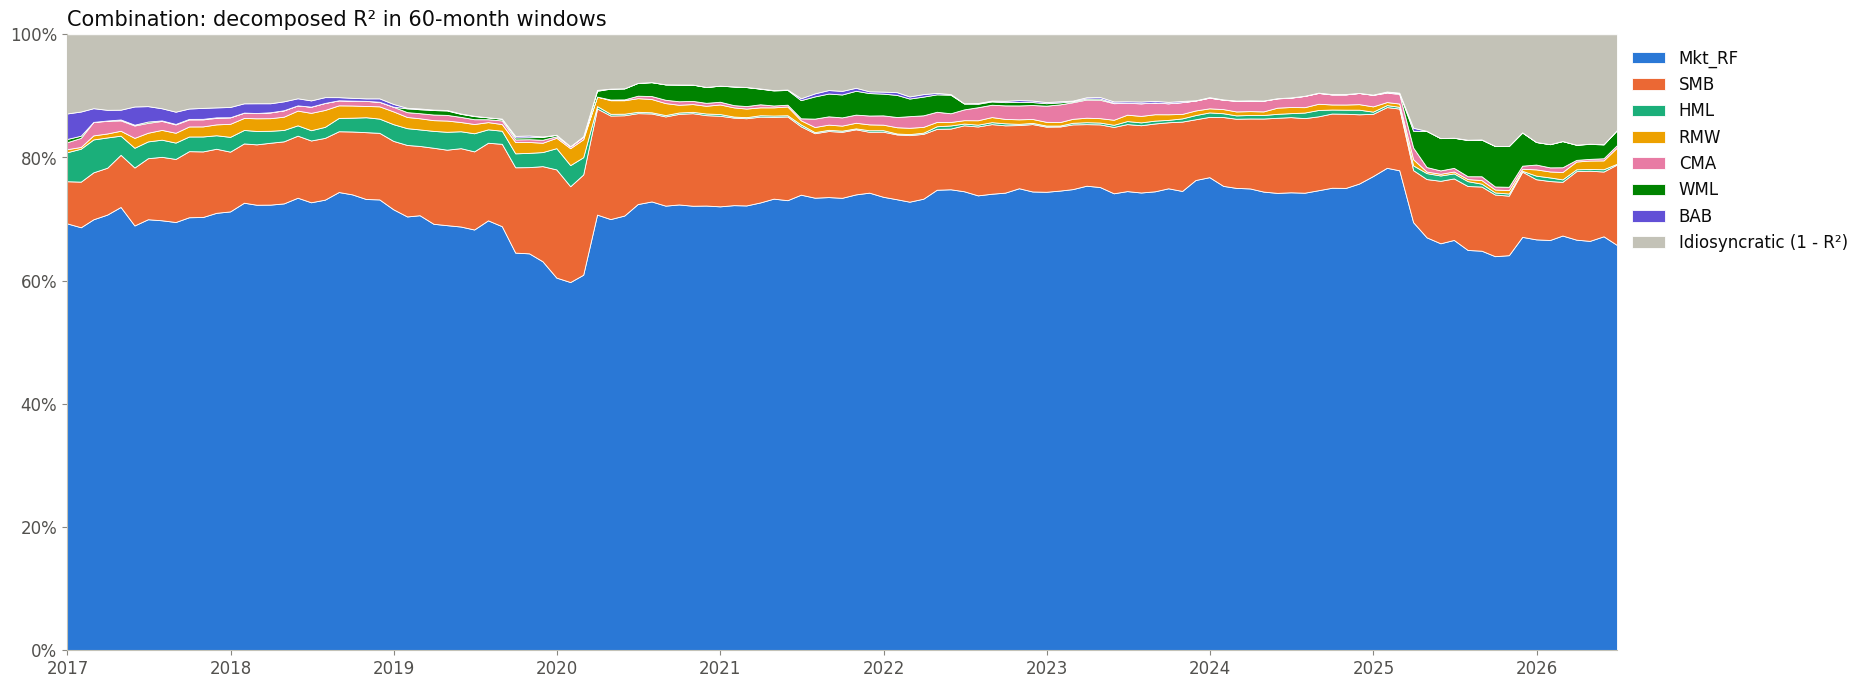

In [3]:
fig, ax = plt.subplots()
plot_decomposition(ax, rolling_monthly['Combination'], BRAZIL_FACTORS, 'Combination: decomposed R² in 60-month windows')
plt.show()

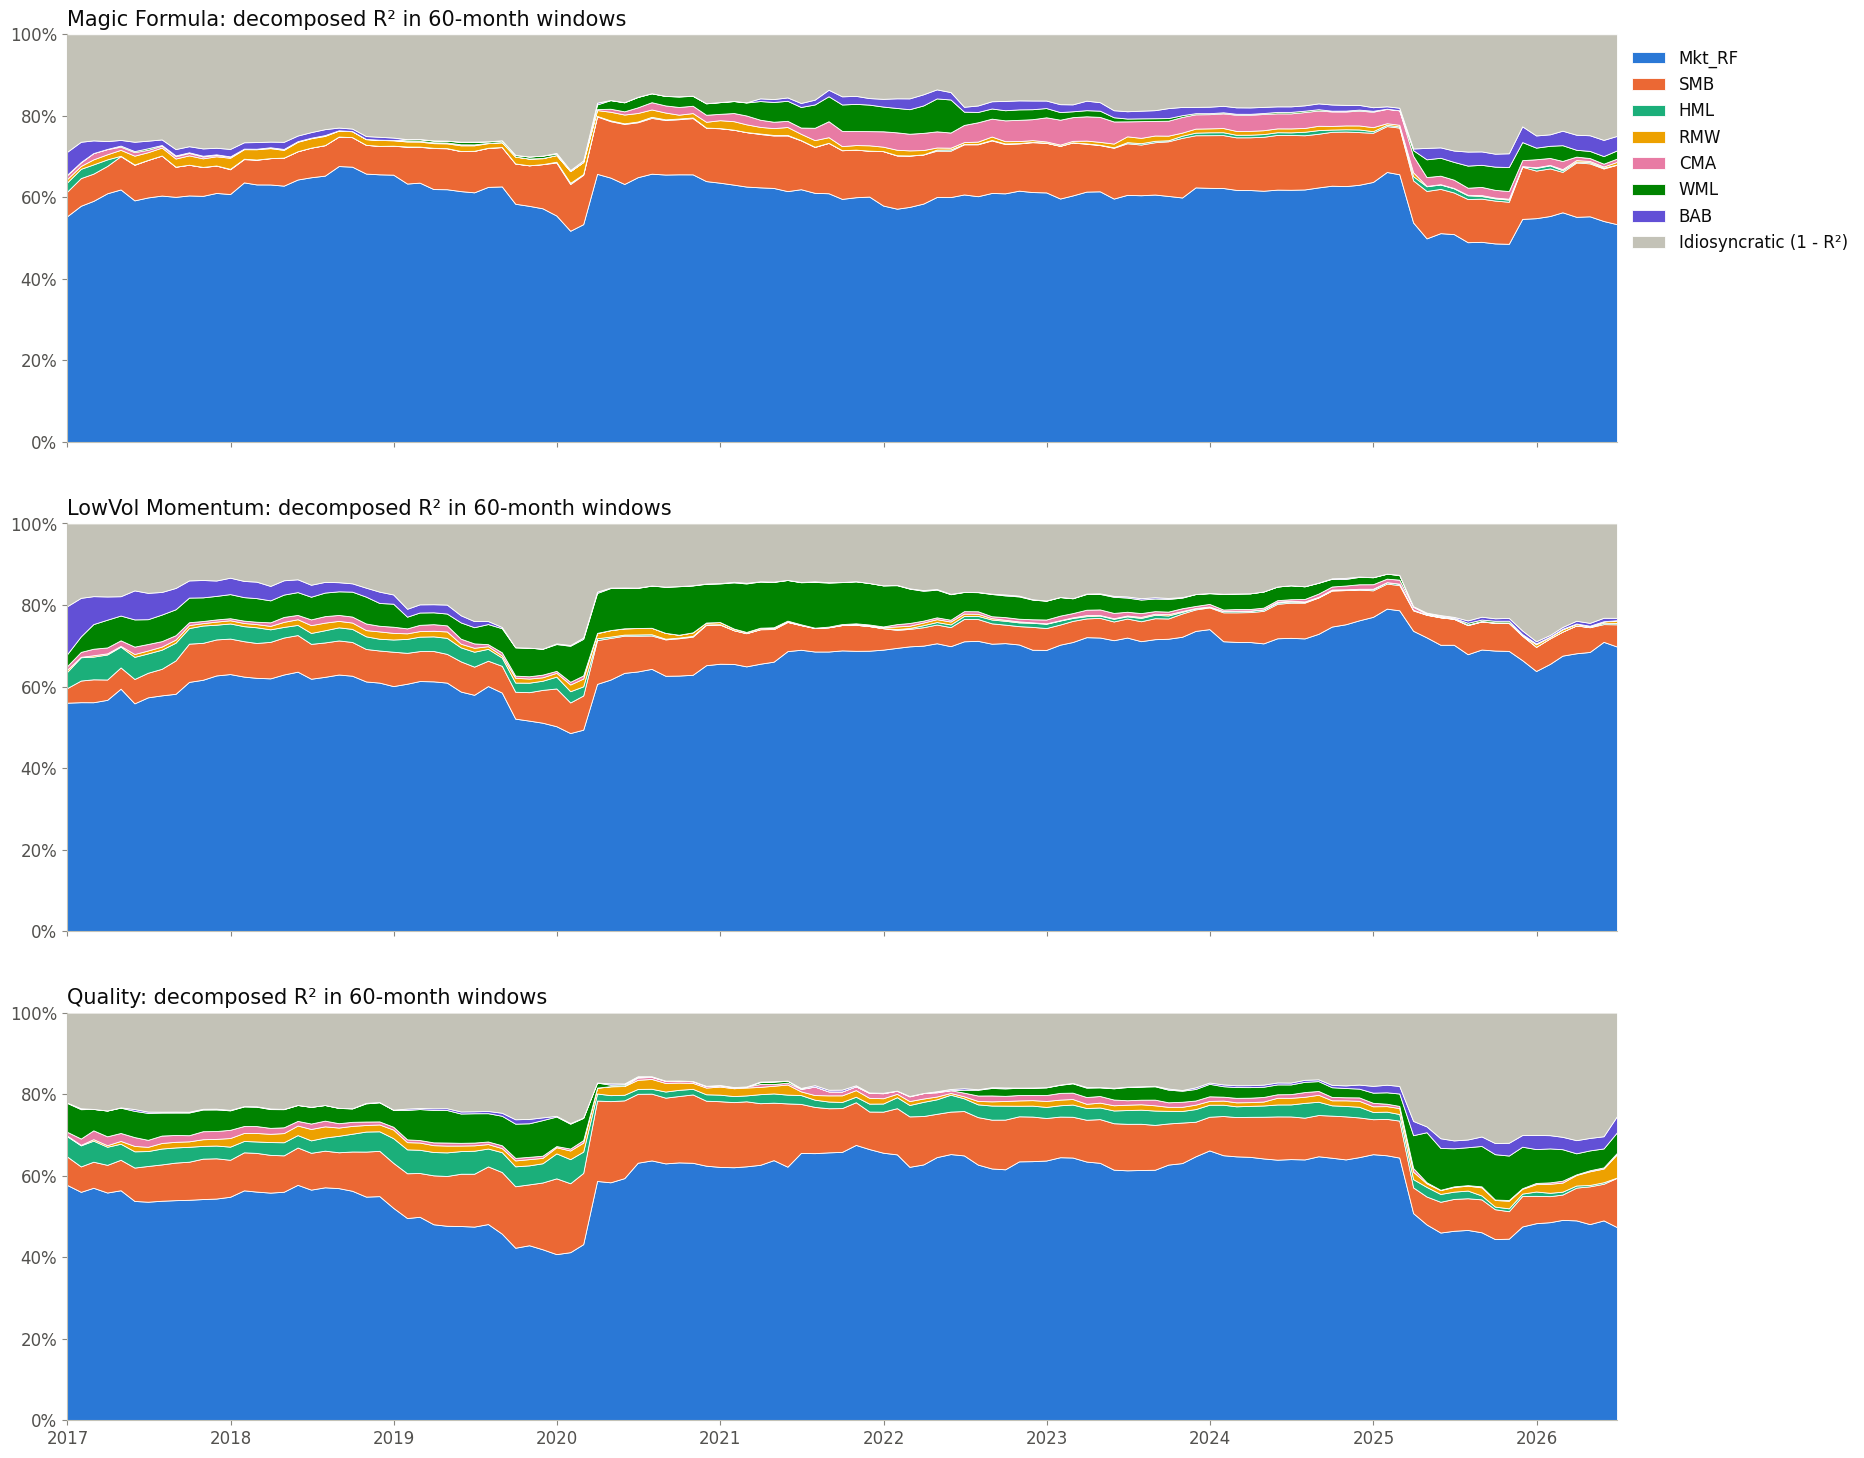

In [4]:
fig, axes = plt.subplots(3, 1, figsize = (20, 18), sharex = True)
for i, (ax, strategy) in enumerate(zip(axes, ['Magic Formula', 'LowVol Momentum', 'Quality'])):
    plot_decomposition(ax, rolling_monthly[strategy], BRAZIL_FACTORS, f'{strategy}: decomposed R² in 60-month windows')
    if i > 0:
        ax.get_legend().remove()
plt.show()

In [5]:
# First and last window, and the range over the windows, for the Combination
combination = rolling_monthly['Combination'][BRAZIL_FACTORS + ['idiosyncratic']]
pd.DataFrame({f'{combination.index[0] - pd.DateOffset(months = 59):%Y-%m} to {combination.index[0]:%Y-%m}': combination.iloc[0],
              f'{combination.index[-1] - pd.DateOffset(months = 59):%Y-%m} to {combination.index[-1]:%Y-%m}': combination.iloc[-1],
              'Lowest': combination.min(), 'Highest': combination.max()}).T.style.format('{:.1%}')

component,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
2012-01 to 2016-12,69.3%,6.8%,4.7%,0.5%,1.1%,0.5%,4.1%,12.9%
2021-07 to 2026-06,65.8%,13.1%,0.1%,2.6%,0.4%,2.4%,0.0%,15.6%
Lowest,59.8%,6.8%,0.1%,0.3%,0.0%,0.0%,0.0%,7.8%
Highest,78.3%,17.6%,5.3%,2.9%,3.0%,6.6%,4.1%,18.2%


In [6]:
# Average of each component over the 60-month windows, by strategy
pd.DataFrame({s: rolling_monthly[s][BRAZIL_FACTORS + ['idiosyncratic']].mean() for s in BRAZIL_STRATEGIES}).T.style.format('{:.1%}')

component,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Combination,71.5%,11.4%,1.2%,1.2%,1.2%,1.4%,0.5%,11.7%
Magic Formula,60.4%,11.1%,0.3%,1.2%,2.2%,1.9%,1.5%,21.4%
LowVol Momentum,65.9%,6.9%,1.4%,0.6%,0.6%,5.3%,1.2%,18.1%
Quality,57.4%,11.0%,2.9%,1.5%,0.9%,3.9%,0.6%,21.6%


The market is always the largest source, with 60% to 78% of the variance of the Combination, and size always comes second. What changed over time is how much size explains: 7% in the first window (2012–2016), when value and BAB still explained 5% and 4%, and 13% in the last one (2021–2026), when BAB explains nothing. Value, profitability, investment and momentum never explained more than about 7%, and the idiosyncratic share stayed between 8% and 18%. The sleeves follow the same pattern, with more momentum in LowVol Momentum (5.3% on average) and in Quality (3.9%).

## 252-day windows

Daily windows react faster. The white dashed lines mark the start of the 2014–2016 recession (second quarter of 2014, as dated by CODACE), the COVID-19 crash of March 2020 and the first increase of the SELIC rate in March 2021, at the start of a cycle that took it from 2% to 13.75%.

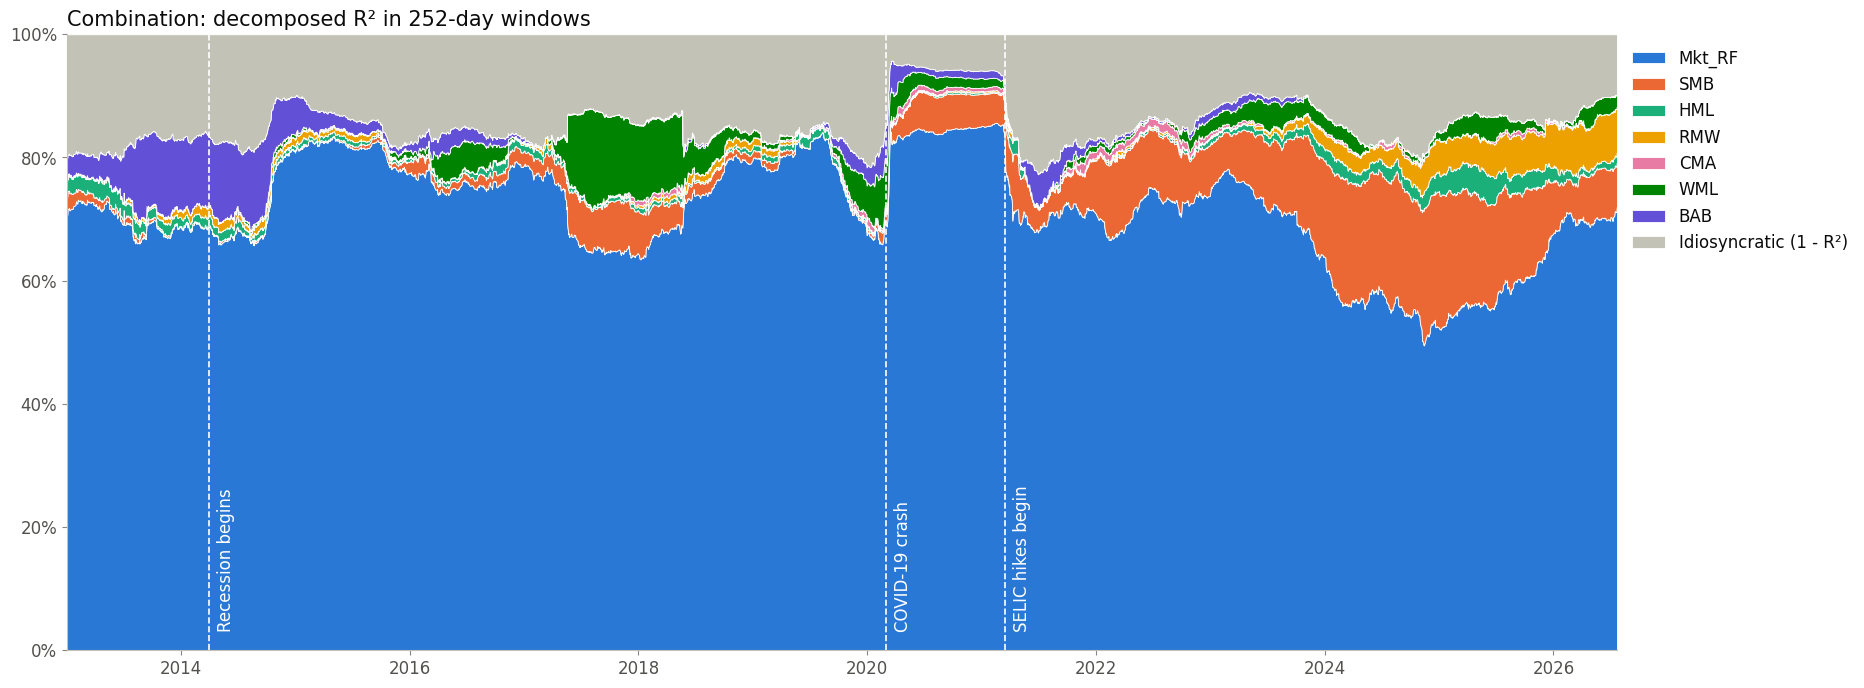

In [7]:
events = {'Recession begins': '2014-04-01', 'COVID-19 crash': '2020-03-01', 'SELIC hikes begin': '2021-03-17'}

fig, ax = plt.subplots()
plot_decomposition(ax, rolling_daily['Combination'], BRAZIL_FACTORS, 'Combination: decomposed R² in 252-day windows')
for label, day in events.items():
    ax.axvline(pd.Timestamp(day), color = '#ffffff', linestyle = '--', linewidth = 1.2)
    ax.text(pd.Timestamp(day) + pd.Timedelta(days = 25), 0.03, label, rotation = 90, ha = 'left', va = 'bottom',
            fontsize = 12, color = '#ffffff')
fig.savefig('docs/combination_rolling_decomposition.png', dpi = 100, bbox_inches = 'tight')
plt.show()

In [8]:
# Average of the daily windows that end in each year
yearly = rolling_daily['Combination'][BRAZIL_FACTORS + ['idiosyncratic']].groupby(rolling_daily.index.year).mean()
lowest = rolling_daily[('Combination', 'idiosyncratic')]
print(f'Lowest idiosyncratic share: {lowest.min():.1%}, in the window that ends on {lowest.idxmin():%Y-%m-%d}')
yearly.style.format('{:.1%}')

Lowest idiosyncratic share: 4.2%, in the window that ends on 2020-03-19


component,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Date,,,,,,,,
2013,70.0%,1.0%,2.2%,0.4%,0.0%,0.1%,8.0%,18.2%
2014,70.4%,0.1%,1.2%,1.3%,0.0%,0.3%,10.7%,15.9%
2015,81.3%,0.5%,0.6%,0.7%,0.1%,0.3%,2.4%,14.1%
2016,76.1%,1.8%,0.9%,0.1%,0.1%,2.8%,1.9%,16.2%
2017,69.6%,5.7%,0.8%,0.3%,0.1%,8.8%,0.1%,14.7%
2018,72.8%,3.0%,0.5%,1.0%,0.3%,6.7%,0.2%,15.3%
2019,78.5%,0.5%,1.0%,0.4%,0.4%,1.6%,0.9%,16.8%
2020,81.1%,4.5%,0.2%,0.2%,0.7%,3.3%,2.0%,8.0%
2021,73.8%,5.6%,0.4%,0.2%,0.6%,0.7%,2.3%,16.4%


The daily windows show when the shift happened. The market explained between 70% and 81% of the daily variance in every year up to 2023. BAB mattered in the windows that end in 2013 and 2014 (8% and 11%), and momentum in 2017 and 2018 (9% and 7%). From 2022 size grew, and in the windows that end in 2024 it explained 20% while the market fell to 56%. Crashes push everything into the market: the lowest idiosyncratic share, 4.2%, is in the window that ends on 2020-03-19, during the COVID-19 crash, when almost all stocks fell together.

The decomposition shows when size became a larger part of the risk, not why. The timing coincides with the high SELIC rates after 2021, when small caps lagged the large ones (see the SMB line in [`02_brazil_factors`](02_brazil_factors.ipynb)), but this notebook does not test a cause.

## How the components move together

The paper finds that the components trade off against each other over time. The heatmap shows the correlations between the 60-month decomposed $R^2$ of each factor for the Combination.

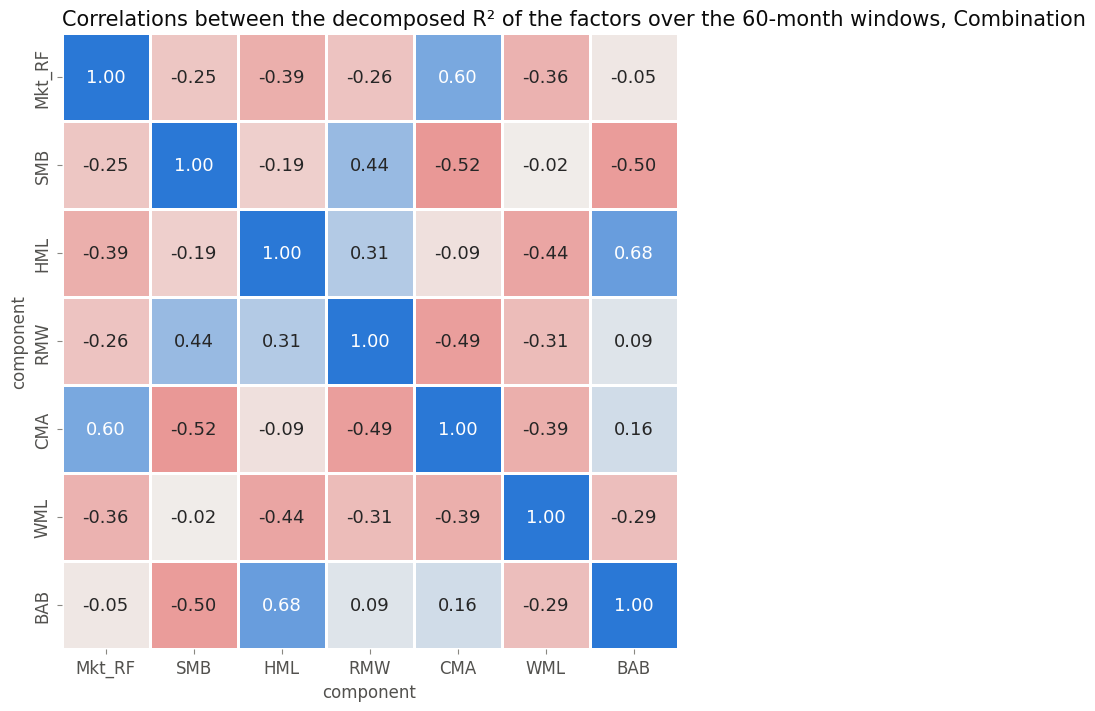

In [9]:
fig, ax = plt.subplots(figsize = (10, 8))
sns.heatmap(combination[BRAZIL_FACTORS].corr().round(2) + 0.0, annot = True, fmt = '.2f', cmap = DIVERGING, vmin = -1, vmax = 1,
            square = True, cbar = False, linewidths = 2, linecolor = 'white', annot_kws = {'size': 13}, ax = ax)
ax.set_title('Correlations between the decomposed R² of the factors over the 60-month windows, Combination')
ax.grid(False)
plt.show()

The shares of value and BAB rise and fall together across the windows, with a correlation of 0.68, and so do those of the market and investment (0.60). Size moves against investment (−0.52) and BAB (−0.50): as the share of size grew, theirs shrank. The shares of the market and of BAB are unrelated (−0.05), unlike with the dollar-neutral BAB of the companion, where they move against each other (−0.72) because that BAB shared the risk of the market.

## How close the orthogonal factors stay to the originals

The resemblance $\text{diag}(\Psi)$ in each 60-month window.

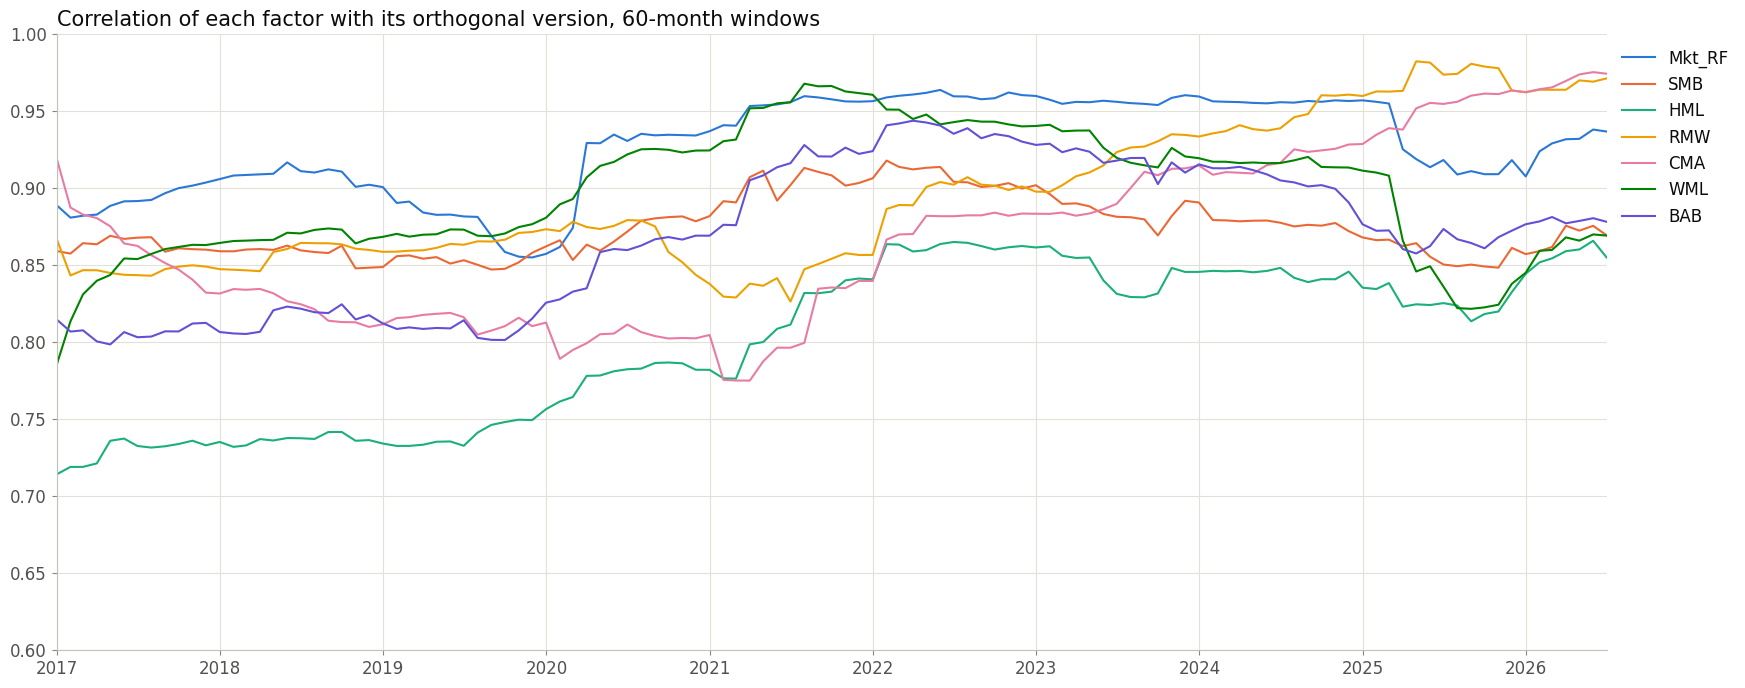

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB
min,0.855,0.847,0.714,0.826,0.775,0.785,0.799
median,0.934,0.869,0.820,0.876,0.870,0.910,0.872
max,0.964,0.918,0.866,0.982,0.975,0.968,0.944


In [10]:
resemblance = {}
for end in range(60, len(factors) + 1):
    _, _, Psi = orthogonalize_swl(factors.iloc[end - 60:end], return_matrices = True)
    resemblance[factors.index[end - 1]] = np.diag(Psi)
resemblance = pd.DataFrame(resemblance, index = BRAZIL_FACTORS).T

fig, ax = plt.subplots()
for factor in BRAZIL_FACTORS:
    ax.plot(resemblance.index, resemblance[factor], color = colors[factor], label = factor)
ax.set_ylim(0.6, 1)
ax.margins(x = 0)
ax.set_title('Correlation of each factor with its orthogonal version, 60-month windows')
ax.legend(loc = 'upper left', bbox_to_anchor = (1.0, 1.0))
plt.show()

resemblance.agg(['min', 'median', 'max']).round(3)

The orthogonal factors stay close to the originals in every window. The median resemblance goes from 0.82 (HML) to 0.93 (the market), and the lowest value of any factor in any window is 0.71, for HML. For five of the seven factors the median is lower than over the full sample, because the factors are often more correlated within shorter periods.

In [11]:
rolling_monthly.round(4).to_csv('results/rolling_decomposition_60_months.csv')
yearly.round(4).to_csv('results/rolling_decomposition_252_days_by_year.csv')